# 🎬 Netflix Movies & TV Shows: Exploratory Data Analysis (EDA)


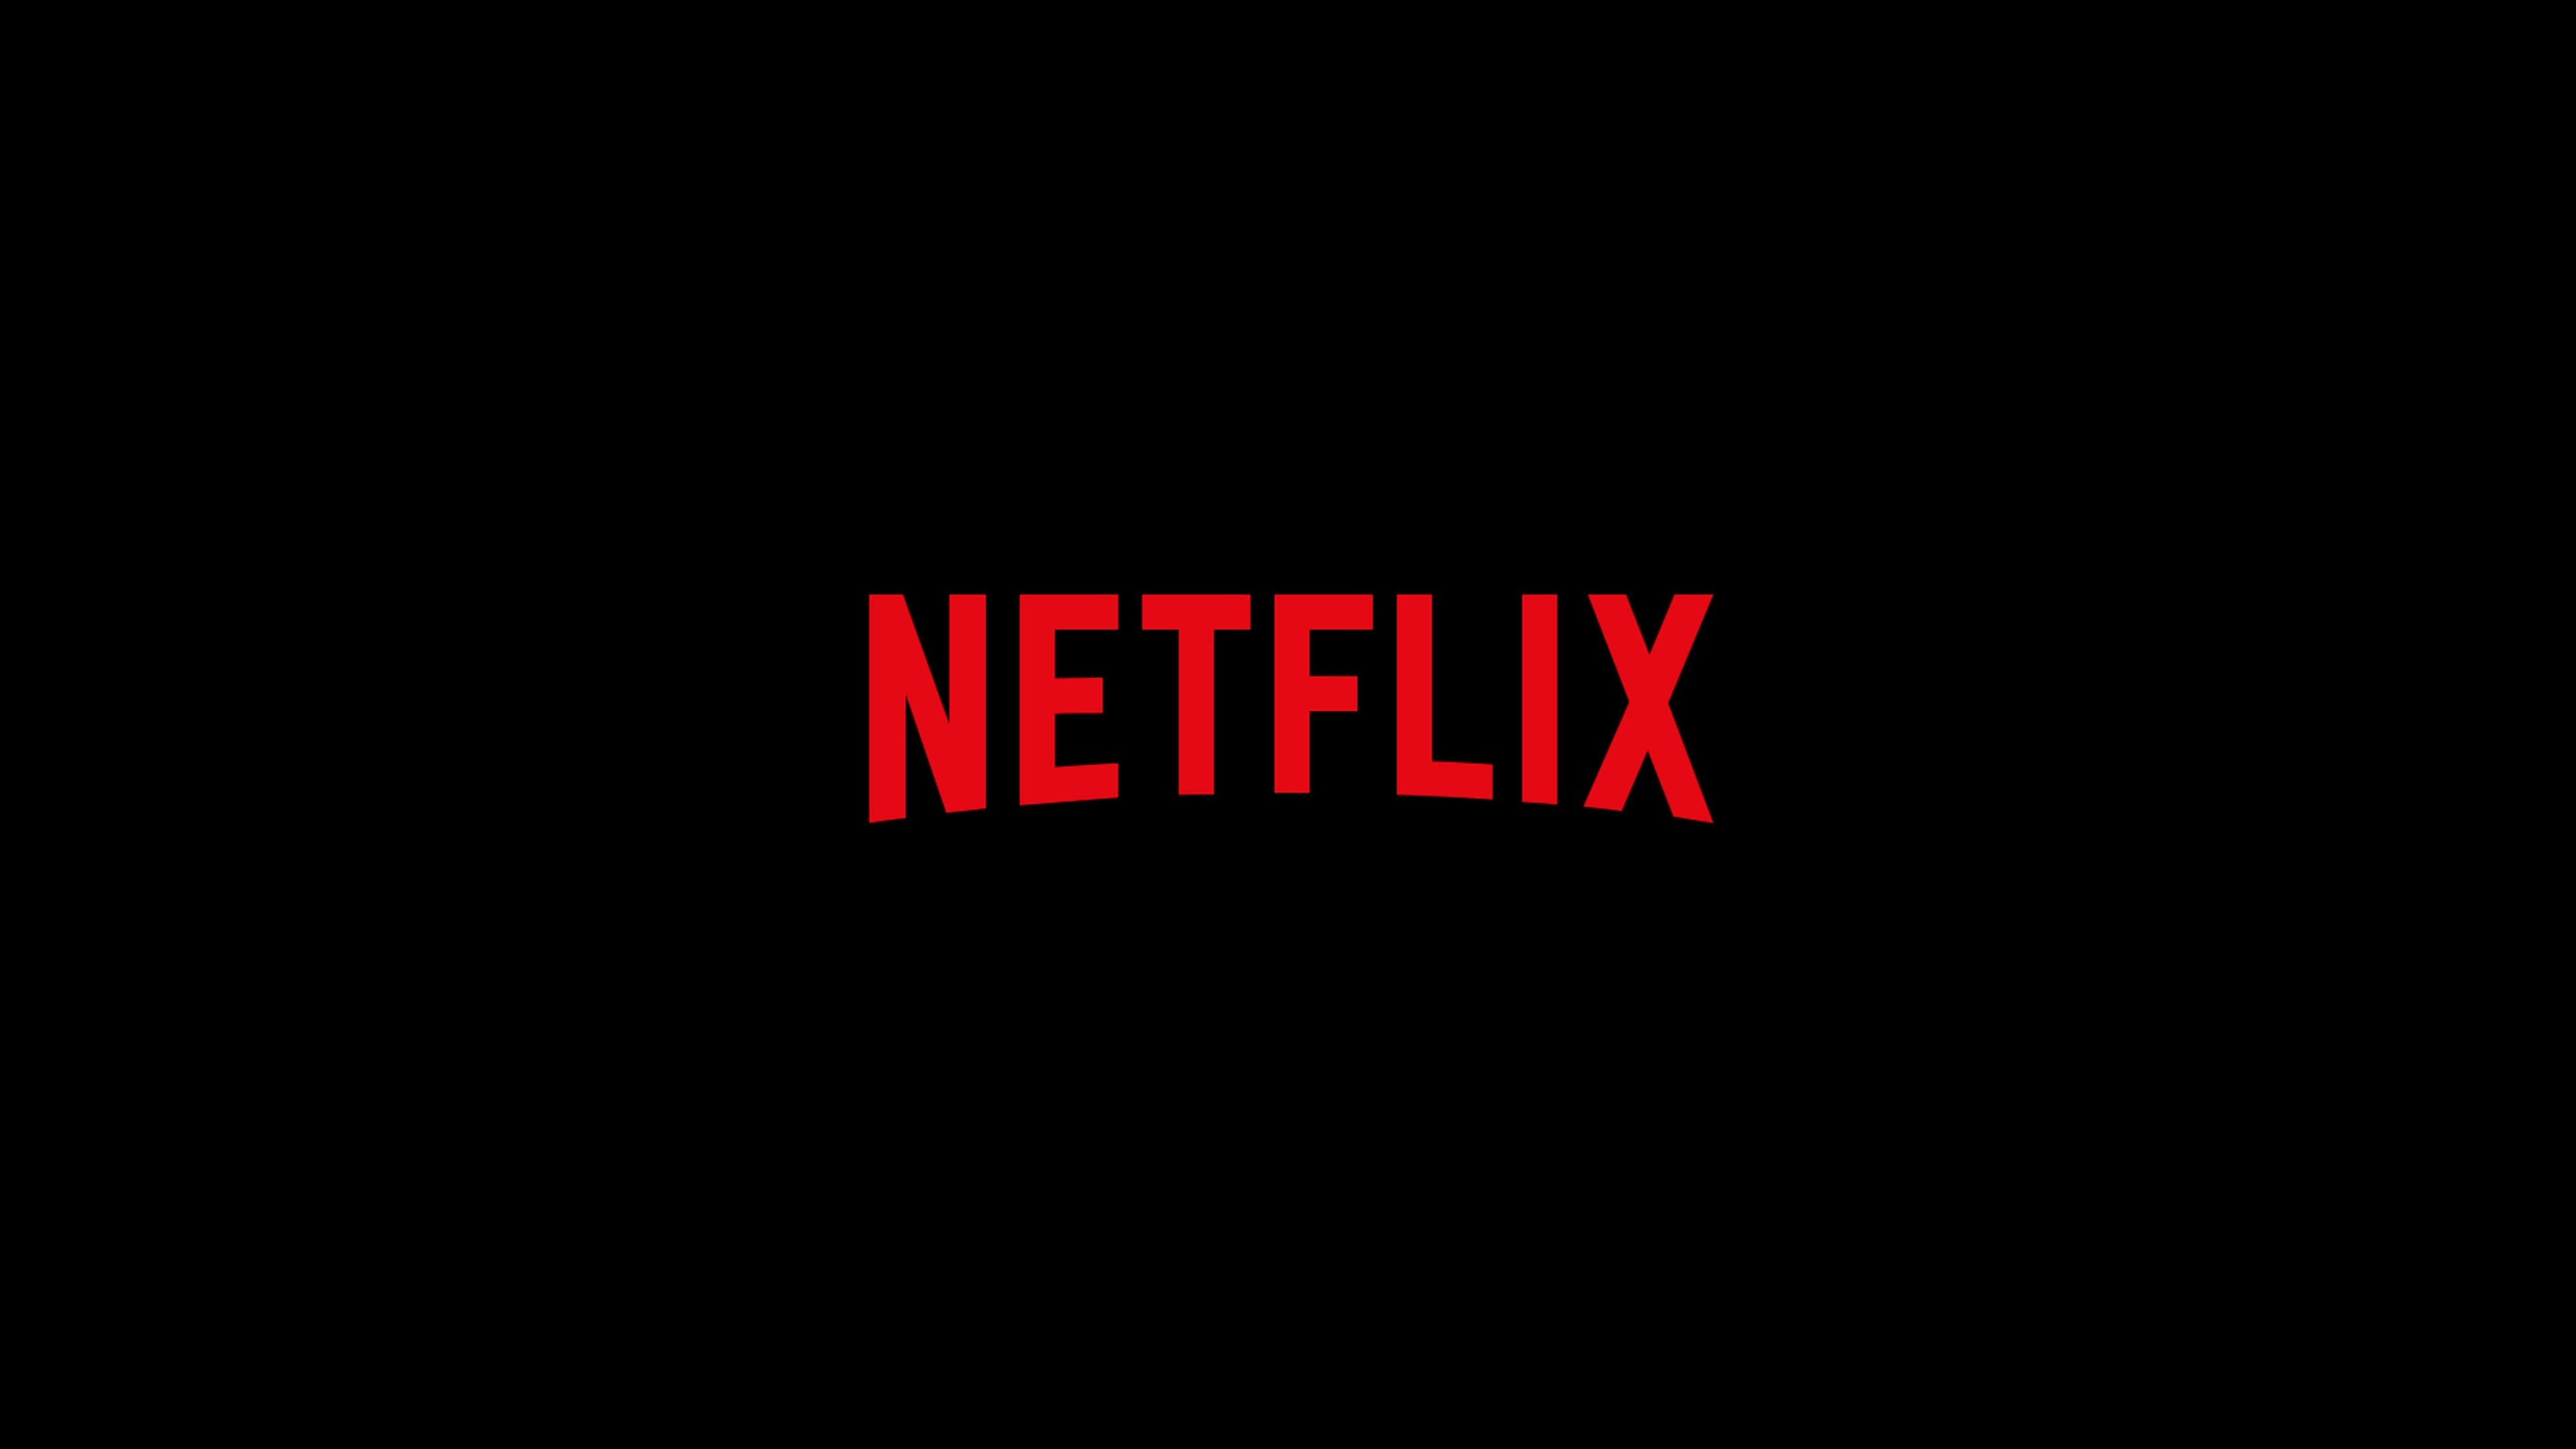

In [1]:
from PIL import Image
img1 = Image.open('/kaggle/input/models/harish280207/netflix-logo/transformers/default/1/116411-3840x2160-desktop-4k-netflix-wallpaper-photo.jpg')
img1

## 📌 Project Summary
This project delivers a comprehensive, multi-dimensional Exploratory Data Analysis (EDA) on the global Netflix content catalog (spanning over 7,700 titles). In the modern streaming landscape, content platforms navigate fierce competition, rapidly evolving viewer habits, and licensing dynamics.

By applying systematic data hygiene, robust type casting, feature engineering, and a rich visualization suite—including **box plots, univariate and multivariate count distributions, pairwise relationship grids (pairplots), kernel density violin plots, and correlation heatmaps**—this study decodes Netflix's content acquisition strategy, format composition, runtime standards, geographic concentrations, and demographic rating profiles.


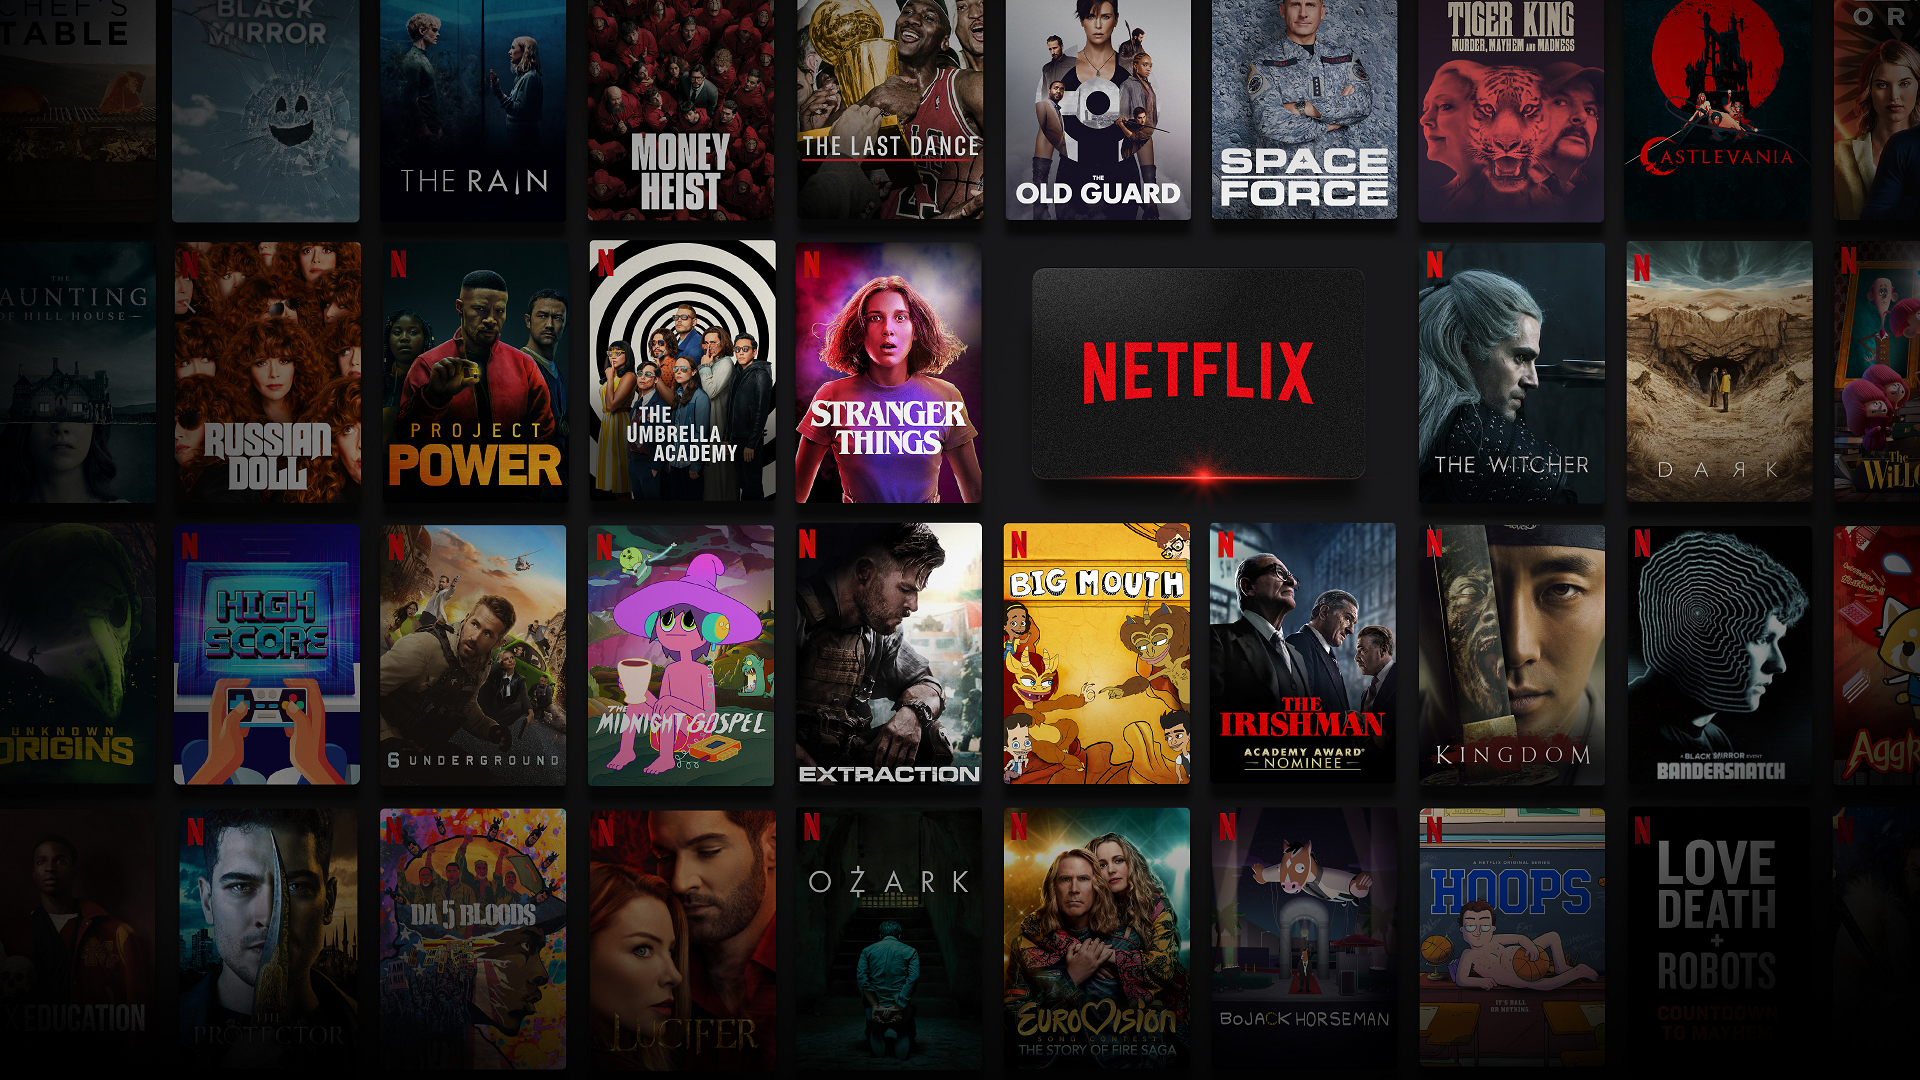

In [2]:
from PIL import Image
img1 = Image.open('/kaggle/input/models/harish280207/netflix-logo/transformers/default/1/2_popular_netflix_tv_shows_return_with_new_seasons_today.webp')
img1

## 📑 Project Index (Table of Contents)
1. **Phase 1: Environment Setup & Library Configuration**
2. **Phase 2: Data Acquisition & Initial Ingestion**
3. **Phase 3: Schema Understanding & Data Dictionary**
4. **Phase 4: Missing Value Diagnostics & Quality Assessment**
5. **Phase 5: Data Cleaning & Preprocessing**
6. **Phase 6: Feature Engineering**
7. **Phase 7: Correlation & Quantitative Outlier Analysis (Heatmap & Box Plots)**
8. **Phase 8: Exploratory Data Analysis & Categorical Visualizations (Count, Pair, Violin Plots)**
9. **Phase 9: Key Business Insights & Strategic Conclusions**


## 1. Environment Setup & Library Configuration
Initialize core Python data science and visualization libraries, configuring consistent plotting styles and figure parameters.


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11


## 2. Data Acquisition & Initial Ingestion
Retrieve the official Netflix Titles dataset and verify initial matrix shape and record structure.


In [4]:
url = "/kaggle/input/datasets/harish280207/netflix-raw-dataset/netflix_raw_dataset.csv"
df = pd.read_csv(url)

print(f"Dataset successfully loaded.")
print(f"Total Records (Rows): {df.shape[0]:,}")
print(f"Total Attributes (Columns): {df.shape[1]}")
df.head()


Dataset successfully loaded.
Total Records (Rows): 7,787
Total Attributes (Columns): 13


,Unnamed: 0,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,0,s1,TV Show,3%,NaN,"João Miguel, Bianca Comparato, Michel Gomes, R...",Brazil,"August 14, 2020",2020,TV-MA,4 Seasons,"International TV Shows, TV Dramas, TV Sci-Fi &...",In a future where the elite inhabit an island ...
1,1,s2,Movie,7:19,Jorge Michel Grau,"Demián Bichir, Héctor Bonilla, Oscar Serrano, ...",Mexico,"December 23, 2016",2016,TV-MA,93 min,"Dramas, International Movies",After a devastating earthquake hits Mexico Cit...
2,2,s3,Movie,23:59,Gilbert Chan,"Tedd Chan, Stella Chung, Henley Hii, Lawrence ...",Singapore,"December 20, 2018",2011,R,78 min,"Horror Movies, International Movies","When an army recruit is found dead, his fellow..."
3,3,s4,Movie,9,Shane Acker,"Elijah Wood, John C. Reilly, Jennifer Connelly...",United States,"November 16, 2017",2009,PG-13,80 min,"Action & Adventure, Independent Movies, Sci-Fi...","In a postapocalyptic world, rag-doll robots hi..."
4,4,s5,Movie,21,Robert Luketic,"Jim Sturgess, Kevin Spacey, Kate Bosworth, Aar...",United States,"January 1, 2020",2008,PG-13,123 min,Dramas,A brilliant group of students become card-coun...


## 3. Schema Understanding & Data Dictionary
Examine underlying schema data types, non-null counts, high-level summary statistics, and cardinalities.

### 📋 Data Dictionary Reference:
- `show_id`: Unique identifier for each title
- `type`: Content category (`Movie` or `TV Show`)
- `title`: Official title of the production
- `director`: Director(s) of the movie/show
- `cast`: Key performers
- `country`: Country or countries of production
- `date_added`: Date the title was ingested onto Netflix
- `release_year`: Original theatrical or broadcast release year
- `rating`: Target audience maturity rating (TV-MA, PG-13, R, etc.)
- `duration`: Length in minutes (Movies) or seasons (TV Shows)
- `listed_in`: Curated genres and category classifications
- `description`: Summary synopsis of the storyline


In [5]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7787 entries, 0 to 7786
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Unnamed: 0    7787 non-null   int64 
 1   show_id       7787 non-null   object
 2   type          7787 non-null   object
 3   title         7787 non-null   object
 4   director      5398 non-null   object
 5   cast          7069 non-null   object
 6   country       7280 non-null   object
 7   date_added    7777 non-null   object
 8   release_year  7787 non-null   int64 
 9   rating        7780 non-null   object
 10  duration      7787 non-null   object
 11  listed_in     7787 non-null   object
 12  description   7787 non-null   object
dtypes: int64(2), object(11)
memory usage: 791.0+ KB


In [6]:
df.describe(include="all").T


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Unnamed: 0,7787.0,NaN,NaN,NaN,3893.0,2248.057606,0.0,1946.5,3893.0,5839.5,7786.0
show_id,7787,7787,s7787,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
type,7787,2,Movie,5377,NaN,NaN,NaN,NaN,NaN,NaN,NaN
title,7787,7787,ZZ TOP: THAT LITTLE OL' BAND FROM TEXAS,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
director,5398,4049,"Raúl Campos, Jan Suter",18,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cast,7069,6831,David Attenborough,18,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,7280,681,United States,2555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date_added,7777,1565,"January 1, 2020",118,NaN,NaN,NaN,NaN,NaN,NaN,NaN
release_year,7787.0,NaN,NaN,NaN,2013.93258,8.757395,1925.0,2013.0,2017.0,2018.0,2021.0
rating,7780,14,TV-MA,2863,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
unique_counts = pd.DataFrame({
    'Unique Values': df.nunique(),
    'Data Type': df.dtypes
}).sort_values(by='Unique Values', ascending=False)
unique_counts


,Unique Values,Data Type
Unnamed: 0,7787,int64
show_id,7787,object
title,7787,object
description,7769,object
cast,6831,object
director,4049,object
date_added,1565,object
country,681,object
listed_in,492,object
duration,216,object


## 4. Missing Value Diagnostics & Quality Assessment
Quantify missingness across attributes to determine appropriate cleaning and imputation policies.


In [8]:
missing_count = df.isna().sum()
missing_percent = (df.isna().mean() * 100).round(2)

missing_summary = pd.DataFrame({
    "Missing Values": missing_count,
    "Missing Percentage (%)": missing_percent
}).sort_values(by="Missing Values", ascending=False)

missing_summary[missing_summary["Missing Values"] > 0]


,Missing Values,Missing Percentage (%)
director,2389,30.68
cast,718,9.22
country,507,6.51
date_added,10,0.13
rating,7,0.09


## 5. Data Cleaning & Preprocessing
Execute targeted data hygiene:
1. Impute missing `director` and `cast` with `"Unknown"`.
2. Impute missing `country` with the statistical mode.
3. Drop rows with negligible missingness in core attributes (`date_added`, `rating`, `duration`).
4. Standardize `date_added` into valid `datetime64[ns]` format.


In [9]:
netflix = df.copy()

netflix["director"] = netflix["director"].fillna("Unknown")
netflix["cast"] = netflix["cast"].fillna("Unknown")

country_mode = netflix["country"].mode(dropna=True)[0]
netflix["country"] = netflix["country"].fillna(country_mode)

netflix = netflix.dropna(subset=["date_added", "rating", "duration"]).copy()
netflix["date_added"] = pd.to_datetime(netflix["date_added"].astype(str).str.strip(), errors="coerce")
netflix = netflix.dropna(subset=["date_added"]).copy()

print(f"Shape before cleaning: {df.shape}")
print(f"Shape after cleaning:  {netflix.shape}")
print(f"Data retention rate:   {(len(netflix)/len(df))*100:.2f}%")


Shape before cleaning: (7787, 13)
Shape after cleaning:  (7770, 13)
Data retention rate:   99.78%


In [10]:
netflix.isnull().sum()


Unnamed: 0      0
show_id         0
type            0
title           0
director        0
cast            0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
description     0
dtype: int64

## 6. Feature Engineering
Enrich the analytical dataset by extracting:
- `year_added`: Ingestion calendar year
- `month_added`: Ingestion month number (1-12)
- `month_name_added`: Ingestion calendar month name
- `duration_num`: Clean integer runtime (minutes for movies, seasons for TV shows)


In [11]:
netflix["year_added"] = netflix["date_added"].dt.year.astype(int)
netflix["month_added"] = netflix["date_added"].dt.month.astype(int)
netflix["month_name_added"] = netflix["date_added"].dt.month_name()

netflix["duration_num"] = netflix["duration"].str.extract(r"(\d+)").astype(float)
netflix[["title", "type", "date_added", "year_added", "month_name_added", "duration", "duration_num"]].head()


,title,type,date_added,year_added,month_name_added,duration,duration_num
0,3%,TV Show,2020-08-14,2020,August,4 Seasons,4.0
1,7:19,Movie,2016-12-23,2016,December,93 min,93.0
2,23:59,Movie,2018-12-20,2018,December,78 min,78.0
3,9,Movie,2017-11-16,2017,November,80 min,80.0
4,21,Movie,2020-01-01,2020,January,123 min,123.0


## 7. Correlation & Quantitative Outlier Analysis
Analyze linear dependencies and inspect the dispersion and outlier profile of numerical variables.


### 7.1 Correlation Matrix & Heatmap
Examine correlations between original release years, platform ingestion years, and numerical durations.


In [12]:
df['duration_num'] = df['duration'].str.extract('(\d+)').astype(float)
df['year_added'] = pd.to_datetime(df['date_added'].str.strip(), errors='coerce').dt.year
num_df = df[['release_year', 'duration_num', 'year_added']].dropna()
num_df.corr()

<>:1: SyntaxWarning: invalid escape sequence '\d'
<>:1: SyntaxWarning: invalid escape sequence '\d'
/tmp/ipykernel_17/907004534.py:1: SyntaxWarning: invalid escape sequence '\d'
  df['duration_num'] = df['duration'].str.extract('(\d+)').astype(float)


,release_year,duration_num,year_added
release_year,1.000000,-0.241608,0.100637
duration_num,-0.241608,1.000000,0.038914
year_added,0.100637,0.038914,1.000000


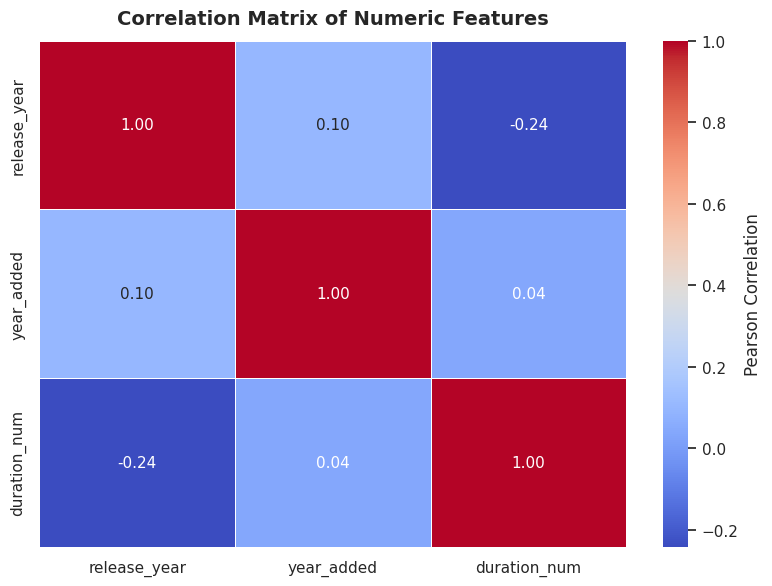

In [13]:
numeric_cols = ["release_year", "year_added", "duration_num"]
num_df = netflix[numeric_cols].dropna()

plt.figure(figsize=(8, 6))
sns.heatmap(num_df.corr(), annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5, cbar_kws={'label': 'Pearson Correlation'})
plt.title("Correlation Matrix of Numeric Features", fontsize=14, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()


### 7.2 Spread & Outlier Detection (Box Plots)
Evaluate skewness, interquartile ranges (IQR), and presence of outliers across numerical attributes.


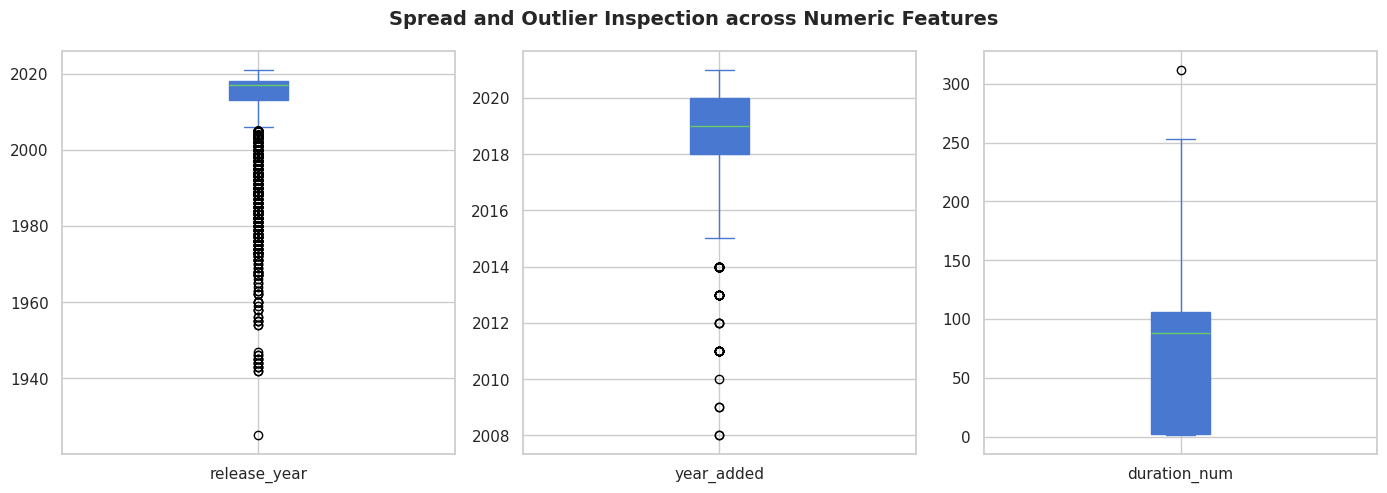

In [14]:
num_df.plot(kind='box', subplots=True, layout=(1, 3), sharex=False, sharey=False, figsize=(14, 5), patch_artist=True)
plt.suptitle("Spread and Outlier Inspection across Numeric Features", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


### 7.3 Multivariate analysis: Movie Runtime by genre

The walkthrough uses a box plot to compare movie runtime across common genres and inspect potential outliers. A box-plot outlier is typically a point beyond the whiskers; it is not automatically an error that must be removed.

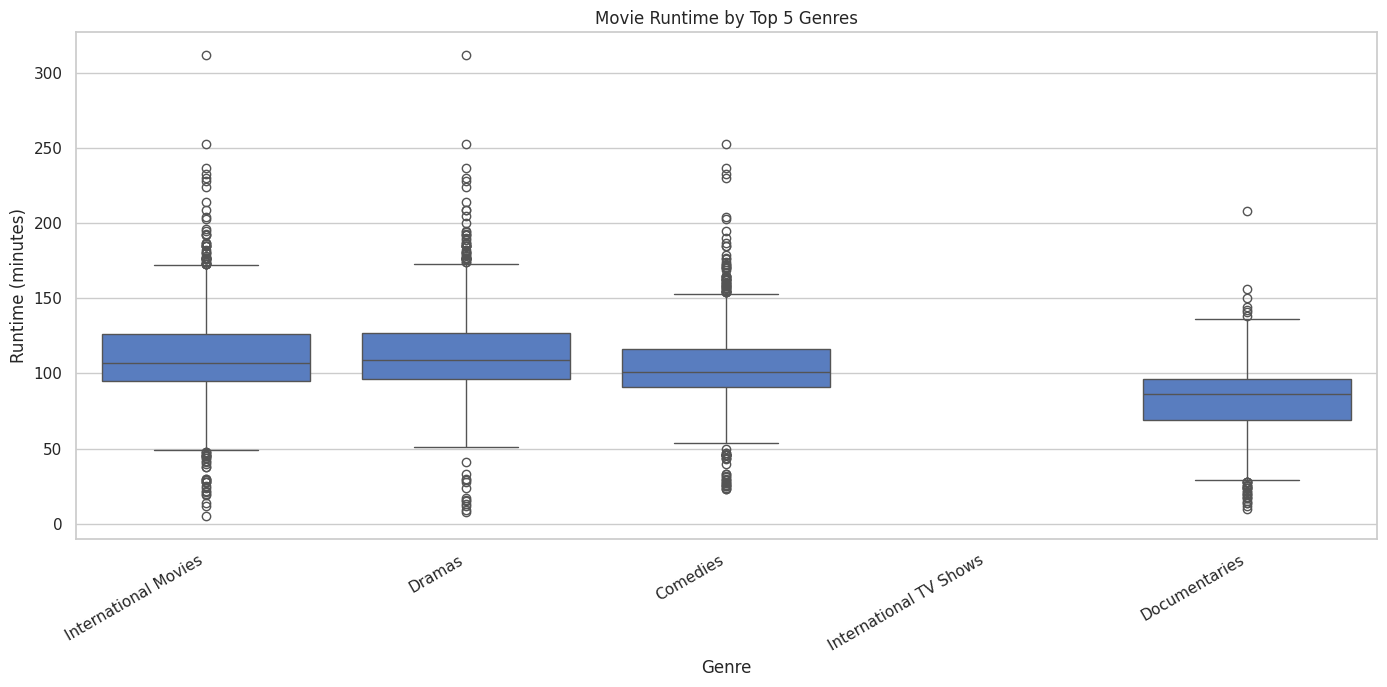

In [15]:

# 1. Parse duration into value and unit
netflix[["duration_value", "duration_unit"]] = netflix["duration"].str.extract(
    r"(\d+)\s*(.*)"
)
netflix["duration_value"] = pd.to_numeric(
    netflix["duration_value"], errors="coerce"
)

# 2. Subset and explode genres
genre_rows = netflix[
    [
        "show_id",
        "type",
        "title",
        "duration_value",
        "duration_unit",
        "listed_in",
    ]
].copy()
genre_rows["genre"] = (
    genre_rows["listed_in"].fillna("").astype(str).str.split(", ")
)
genre_rows = genre_rows.explode("genre")
genre_rows["genre"] = genre_rows["genre"].str.strip()

# Expand each title into one row per genre.
genre_rows = netflix[["show_id", "type", "title", "duration_value", "duration_unit", "listed_in"]].copy()
genre_rows["genre"] = genre_rows["listed_in"].fillna("").astype(str).str.split(", ")
genre_rows = genre_rows.explode("genre")
genre_rows["genre"] = genre_rows["genre"].str.strip()

# Determine the five most frequent genres, then compare movie runtimes for those genres.
top_5_genres = genre_rows["genre"].value_counts().head(5).index.tolist()

movie_genre_runtime = genre_rows[
    (genre_rows["type"] == "Movie") &
    (genre_rows["duration_unit"] == "min") &
    (genre_rows["genre"].isin(top_5_genres))
].copy()

plt.figure(figsize=(14, 7))
sns.boxplot(
    data=movie_genre_runtime,
    x="genre",
    y="duration_value",
    order=top_5_genres
)
plt.title("Movie Runtime by Top 5 Genres")
plt.xlabel("Genre")
plt.ylabel("Runtime (minutes)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig("netflix_movie_runtime_boxplot.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Exploratory Data Analysis & Categorical Visualizations


### 8.1 Catalog Composition: Movies vs. TV Shows
Assess the proportion of feature-length films compared to episodic TV series in the catalog.


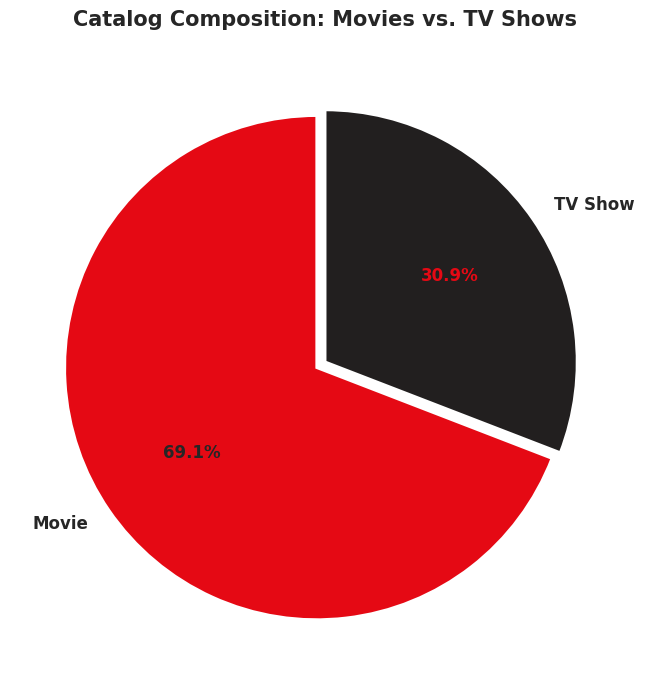

In [16]:
type_counts = netflix["type"].value_counts()

plt.figure(figsize=(7, 7))

# 1. Capture autotexts from plt.pie
wedges, texts, autotexts = plt.pie(
    type_counts.values,
    labels=type_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=["#e50914", "#221f1f"],
    explode=(0.04, 0),
    wedgeprops={"edgecolor": "white", "linewidth": 2},
    textprops={"fontsize": 12, "weight": "bold"},
)

# 2. Change the 30.4% text color to red (index 1 is TV Show)
autotexts[1].set_color("#e50914")

plt.title(
    "Catalog Composition: Movies vs. TV Shows",
    fontsize=15,
    fontweight="bold",
    pad=15,
)
plt.tight_layout()
plt.show()

### 8.2 Ingestion Trajectory: Content Additions Over Time
Track the timeline of content ingestion onto Netflix across calendar years by format.


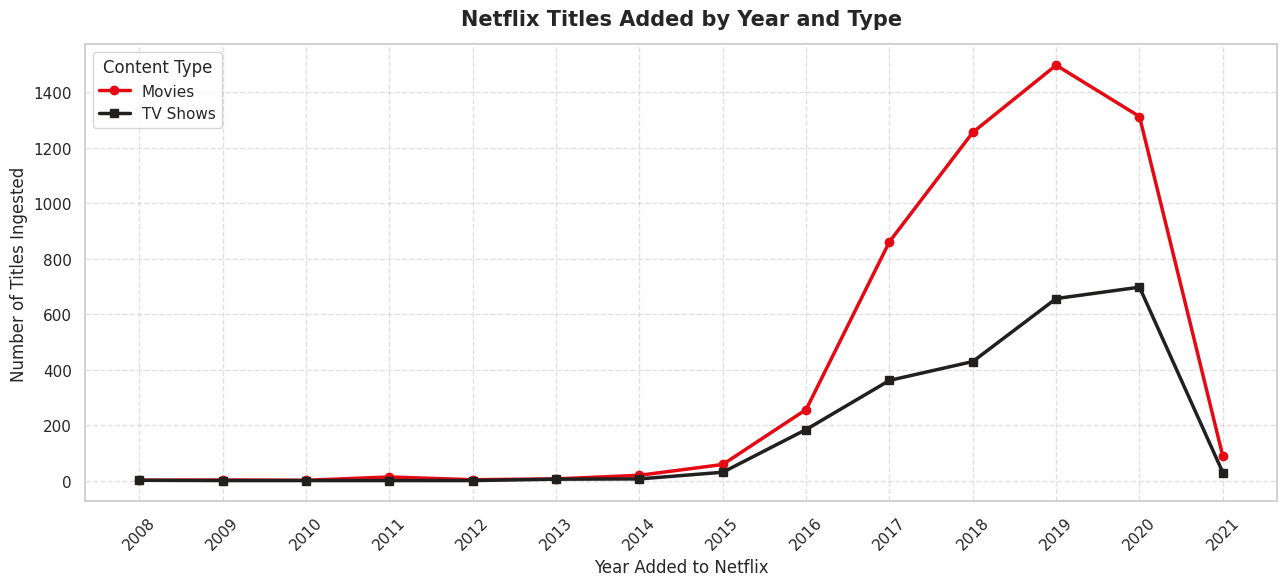

In [17]:
yearly_content = netflix.groupby(["year_added", "type"]).size().unstack(fill_value=0)

plt.figure(figsize=(13, 6))
plt.plot(yearly_content.index, yearly_content["Movie"], marker='o', linewidth=2.5, color="#e50914", label="Movies")
plt.plot(yearly_content.index, yearly_content["TV Show"], marker='s', linewidth=2.5, color="#221f1f", label="TV Shows")

plt.title("Netflix Titles Added by Year and Type", fontsize=15, fontweight='bold', pad=14)
plt.xlabel("Year Added to Netflix", fontsize=12)
plt.ylabel("Number of Titles Ingested", fontsize=12)
plt.xticks(yearly_content.index, rotation=45)
plt.legend(title="Content Type", frameon=True)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()


### 8.2.1 Age of content when it was added

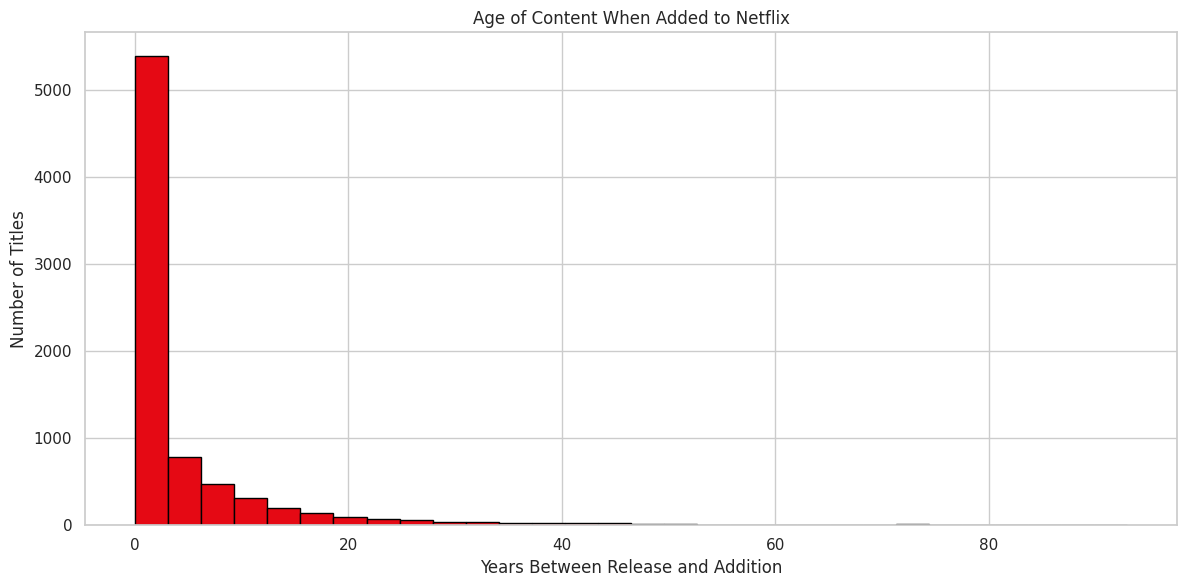

In [18]:
netflix["content_age_at_addition"] = (
    netflix["year_added"] - netflix["release_year"]
)

# Exclude negative ages, which can indicate inconsistent or incomplete dates.
content_age = netflix.loc[
    netflix["content_age_at_addition"] >= 0,
    "content_age_at_addition"
].dropna()

plt.figure(figsize=(12, 6))
plt.hist(content_age, bins=30, edgecolor="black",color="#e50914")
plt.title("Age of Content When Added to Netflix")
plt.xlabel("Years Between Release and Addition")
plt.ylabel("Number of Titles")
plt.tight_layout()
plt.show()

### 8.2.2 Top countries by title count

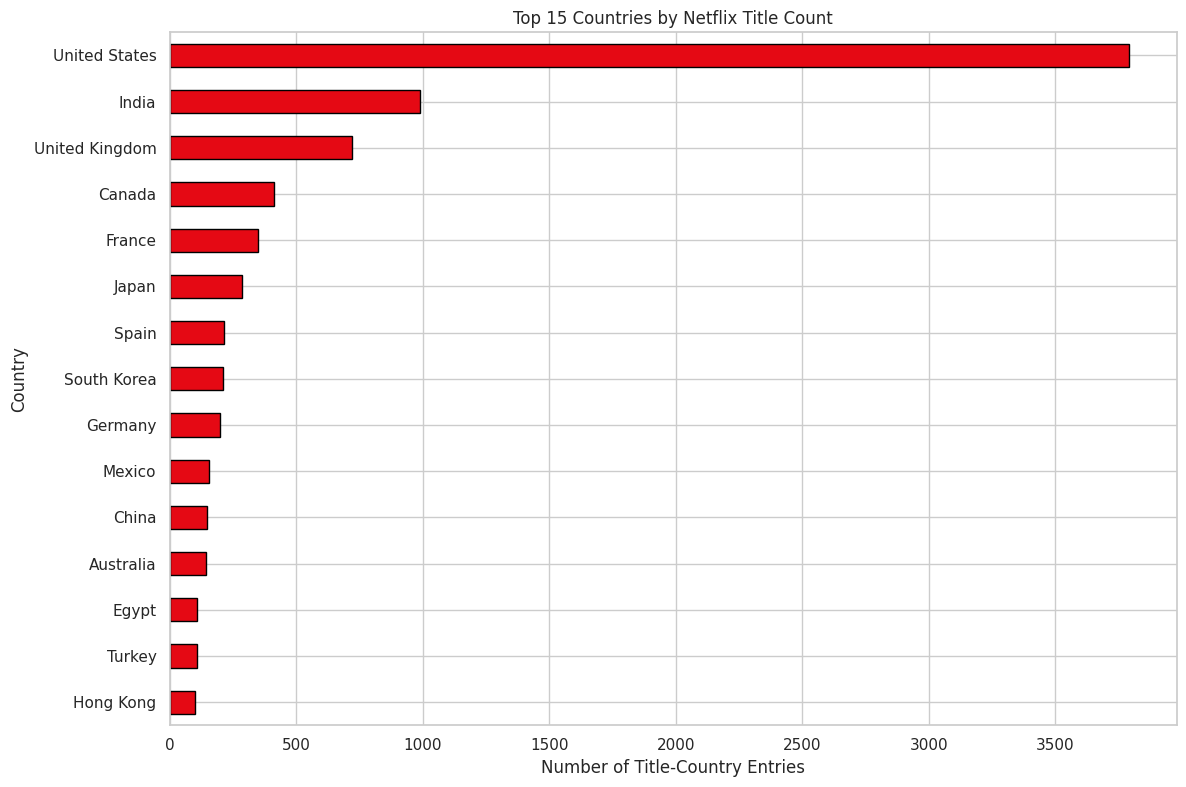

country
United States     3792
India              990
United Kingdom     721
Canada             412
France             349
Japan              285
Spain              215
South Korea        212
Germany            199
Mexico             154
China              147
Australia          142
Egypt              110
Turkey             108
Hong Kong          102
Name: count, dtype: int64

In [19]:
country_counts = (
    netflix["country"]
    .dropna()
    .astype(str)
    .str.split(", ")
    .explode()
    .str.strip()
    .replace("", np.nan)
    .dropna()
    .value_counts()
)

top_15_countries = country_counts.head(15).sort_values()

plt.figure(figsize=(12, 8))
top_15_countries.plot(kind="barh",edgecolor="black",color="#e50914")
plt.title("Top 15 Countries by Netflix Title Count")
plt.xlabel("Number of Title-Country Entries")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

country_counts.head(15)

### 8.2.3 Maturity-rating distribution

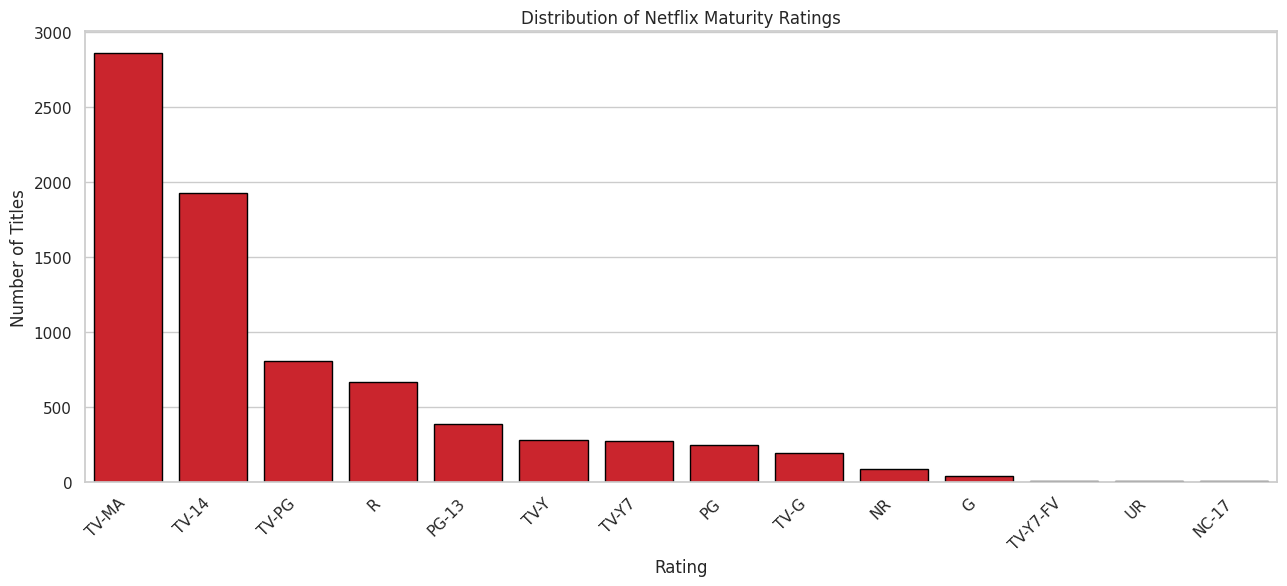

rating
TV-MA       2861
TV-14       1928
TV-PG        804
R            665
PG-13        386
TV-Y         279
TV-Y7        270
PG           247
TV-G         194
NR            83
G             39
TV-Y7-FV       6
UR             5
NC-17          3
Name: count, dtype: int64

In [20]:
rating_counts = netflix["rating"].value_counts()

plt.figure(figsize=(13, 6))
sns.countplot(
    data=netflix,
    x="rating",
    order=rating_counts.index,
    edgecolor="black",color="#e50914"
)
plt.title("Distribution of Netflix Maturity Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

rating_counts

### 8.3 Univariate Distributions: Format, Top Ratings & Producing Countries
Explore univariate distributions across content categories, target audience ratings, and leading country producers.


### Rating Categories

In [21]:
import pandas as pd

data = {
    "Rating": [
        "TV-MA", "TV-14", "TV-PG", "R", "PG-13", "TV-Y", "TV-Y7",
        "PG", "TV-G", "NR", "G", "TV-Y7-FV", "UR", "NC-17"
    ],

    "Age_Group": [
        "Adults (18+)", "Teens (14+)", "Older Kids (10+)", "Adults (17+)", "Teens (13+)", "Kids (2+)", "Kids (7+)",
        "Older Kids (10+)", "All Ages", "Varies", "All Ages", "Kids (7+)", "Varies", "Adults (18+)"
    ],
    "Meaning": [
        "Mature Audience Only (explicit violence, sex, profanity)",
        "Parents Strongly Cautioned (unsuitable for under 14)",
        "Parental Guidance Suggested (mild violence, language, or themes)",
        "Restricted (under 17 requires adult guardian)",
        "Parents Strongly Cautioned (inappropriate for under 13)",
        "All Children (appropriate for preschool/young children)",
        "Directed to Older Children (mild fantasy or comedic violence)",
        "Parental Guidance Suggested (some material may not suit children)",
        "General Audience (suitable for all viewers)",
        "Not Rated (not formally submitted for classification)",
        "General Audiences (all ages admitted, no offensive material)",
        "Directed to Older Children with Fantasy Violence",
        "Unrated (often extended or director's cuts)",
        "Adults Only (no one 17 and under admitted)"
    ]
}

# Create DataFrame
df_ratings = pd.DataFrame(data)

# Display DataFrame
df_ratings

,Rating,Age_Group,Meaning
0,TV-MA,Adults (18+),"Mature Audience Only (explicit violence, sex, ..."
1,TV-14,Teens (14+),Parents Strongly Cautioned (unsuitable for und...
2,TV-PG,Older Kids (10+),"Parental Guidance Suggested (mild violence, la..."
3,R,Adults (17+),Restricted (under 17 requires adult guardian)
4,PG-13,Teens (13+),Parents Strongly Cautioned (inappropriate for ...
5,TV-Y,Kids (2+),All Children (appropriate for preschool/young ...
6,TV-Y7,Kids (7+),Directed to Older Children (mild fantasy or co...
7,PG,Older Kids (10+),Parental Guidance Suggested (some material may...
8,TV-G,All Ages,General Audience (suitable for all viewers)
9,NR,Varies,Not Rated (not formally submitted for classifi...


### Count Plots

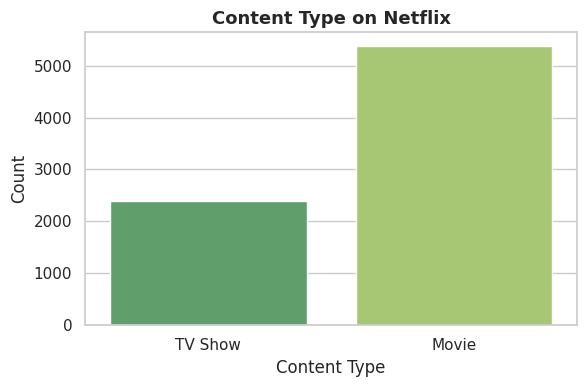

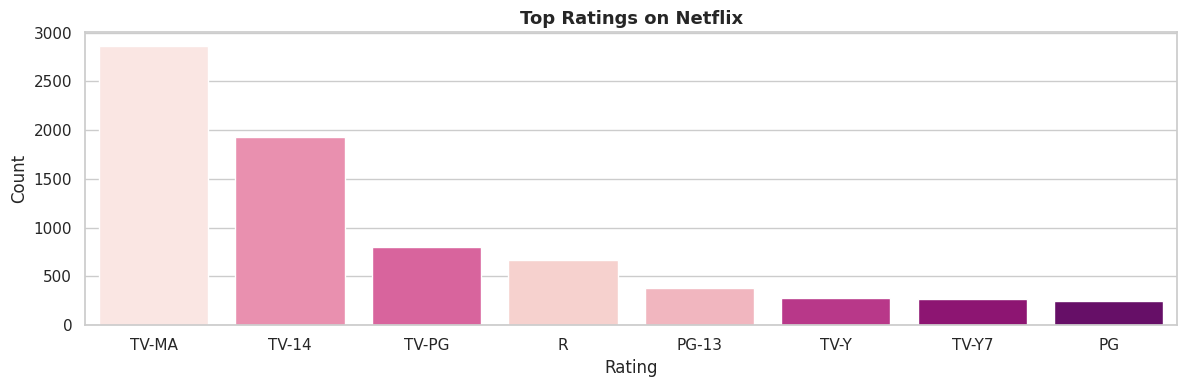

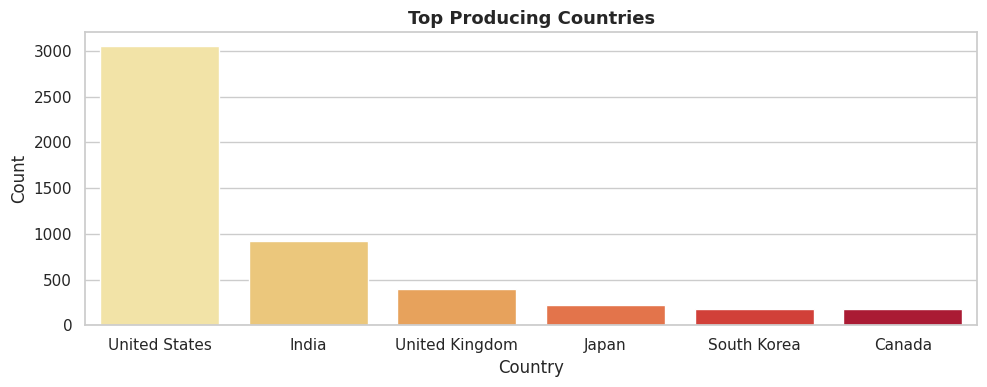

In [22]:
# 1. Content Type
plt.figure(figsize=(6, 4))
sns.countplot(data=netflix, x='type', hue='type', palette='summer', legend=False)
plt.title("Content Type on Netflix", fontsize=13, fontweight='bold')
plt.xlabel("Content Type")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

# 2. Top Ratings
plt.figure(figsize=(12, 4))
top_ratings = netflix['rating'].value_counts().index[:8]
sns.countplot(data=netflix[netflix['rating'].isin(top_ratings)], x='rating', hue='rating', palette='RdPu', order=top_ratings, legend=False)
plt.title("Top Ratings on Netflix", fontsize=13, fontweight='bold')
plt.xlabel("Rating")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

# 3. Top Producing Countries
plt.figure(figsize=(10, 4))
top_countries = netflix['country'].value_counts().index[:6]
sns.countplot(data=netflix[netflix['country'].isin(top_countries)], x='country', hue='country', palette='YlOrRd', order=top_countries, legend=False)
plt.title("Top Producing Countries", fontsize=13, fontweight='bold')
plt.xlabel("Country")
plt.ylabel("Count")
plt.tight_layout()
plt.show()


### 8.4 Multivariate Analysis: Demographic & Geographic Breakdown by Type
Cross-tabulate target audience maturity ratings and country volume segmented by media format (`type`).


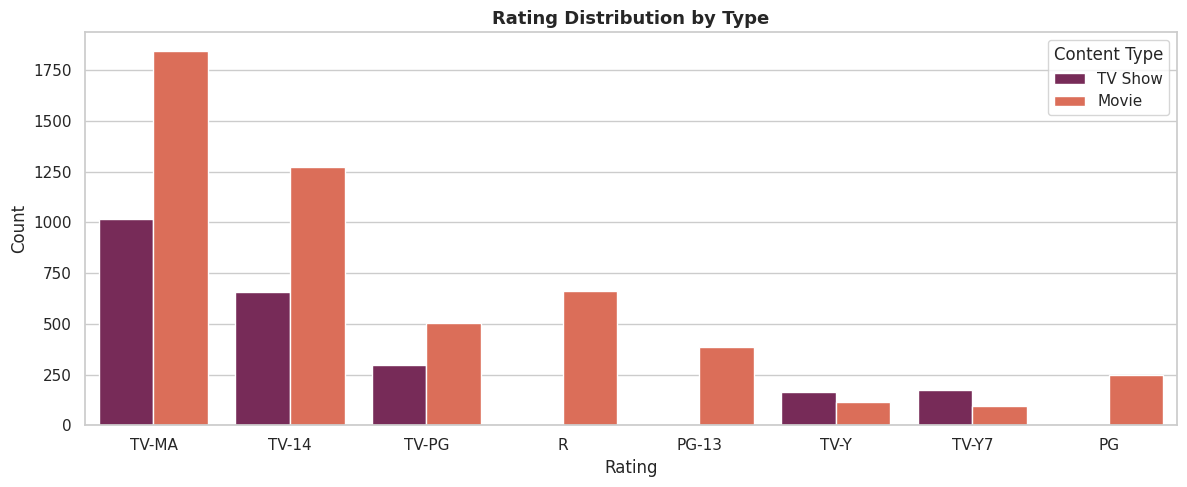

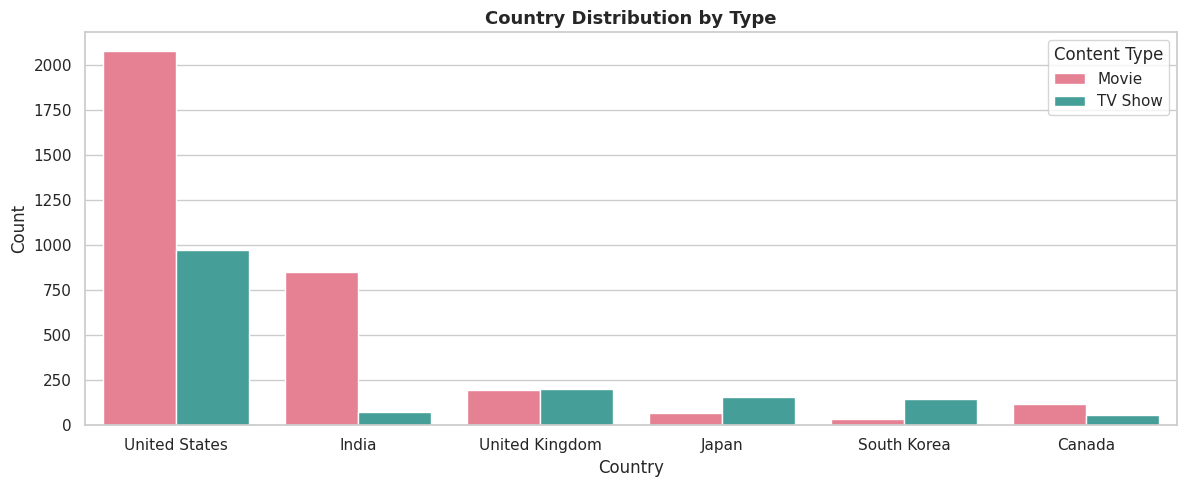

In [23]:
# Rating Distribution by Type
plt.figure(figsize=(12, 5))
sns.countplot(data=netflix[netflix['rating'].isin(top_ratings)], x='rating', palette='rocket', hue='type', order=top_ratings)
plt.title("Rating Distribution by Type", fontsize=13, fontweight='bold')
plt.xlabel("Rating")
plt.ylabel("Count")
plt.legend(title="Content Type")
plt.tight_layout()
plt.show()

# Country Distribution by Type
plt.figure(figsize=(12, 5))
sns.countplot(data=netflix[netflix['country'].isin(top_countries)], x='country', hue='type', palette='husl', order=top_countries)
plt.title("Country Distribution by Type", fontsize=13, fontweight='bold')
plt.xlabel("Country")
plt.ylabel("Count")
plt.legend(title="Content Type")
plt.tight_layout()
plt.show()


### 8.5 Pairwise Feature Relationships: Bivariate Grid
Examine bivariate correlations, pairwise clusters, and kernel density curves across numeric features separated by content type.


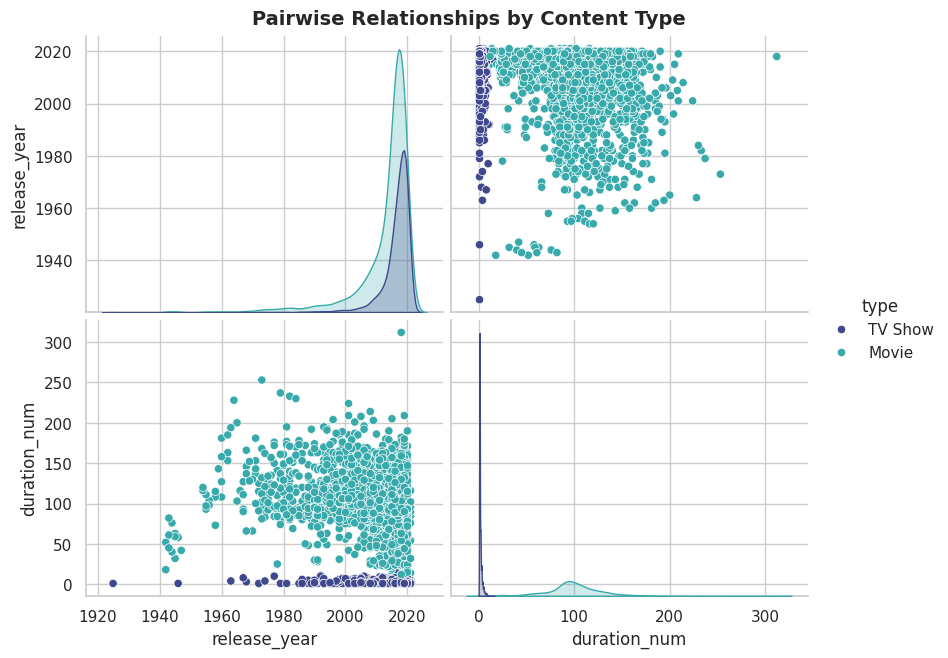

In [24]:
pair_df = netflix[['release_year', 'duration_num', 'type']].dropna()
sns.pairplot(data=pair_df, hue='type', palette='mako', height=3.2, aspect=1.3)
plt.suptitle("Pairwise Relationships by Content Type", y=1.02, fontsize=14, fontweight='bold')
plt.show()


### 8.6 Temporal Density & Demographic Spread across Formats (Violin Plots)
Visualize multimodal kernel density shapes of release years across media types and top audience maturity ratings.


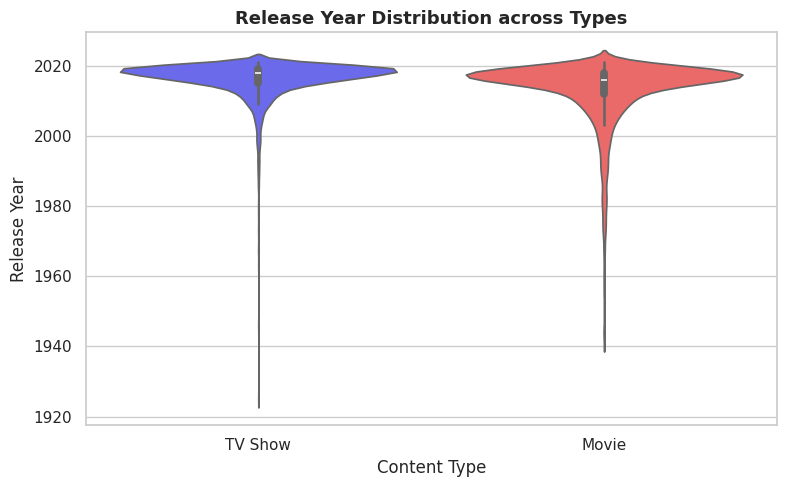

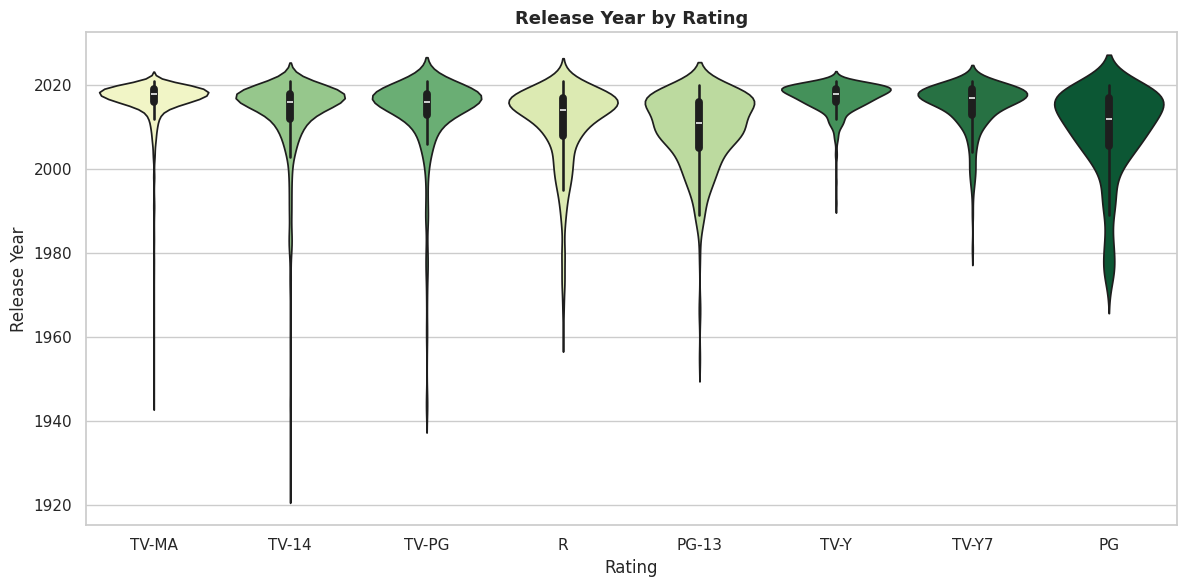

In [25]:
# 1. Release Year across Types
plt.figure(figsize=(8, 5))
sns.violinplot(x='type', y='release_year', data=netflix, hue='type', palette='seismic', legend=False)
plt.title("Release Year Distribution across Types", fontsize=13, fontweight='bold')
plt.xlabel("Content Type")
plt.ylabel("Release Year")
plt.tight_layout()
plt.show()

# 2. Release Year by Rating
plt.figure(figsize=(12, 6))
sns.violinplot(x='rating', y='release_year', data=netflix[netflix['rating'].isin(top_ratings)], hue='rating', palette='YlGn', order=top_ratings, legend=False)
plt.title("Release Year by Rating", fontsize=13, fontweight='bold')
plt.xlabel("Rating")
plt.ylabel("Release Year")
plt.tight_layout()
plt.show()


### 8.7 Genre and Category Popularity Analysis
Decompose multi-label category tags (`listed_in`) into distinct genre instances to uncover top streaming categories.


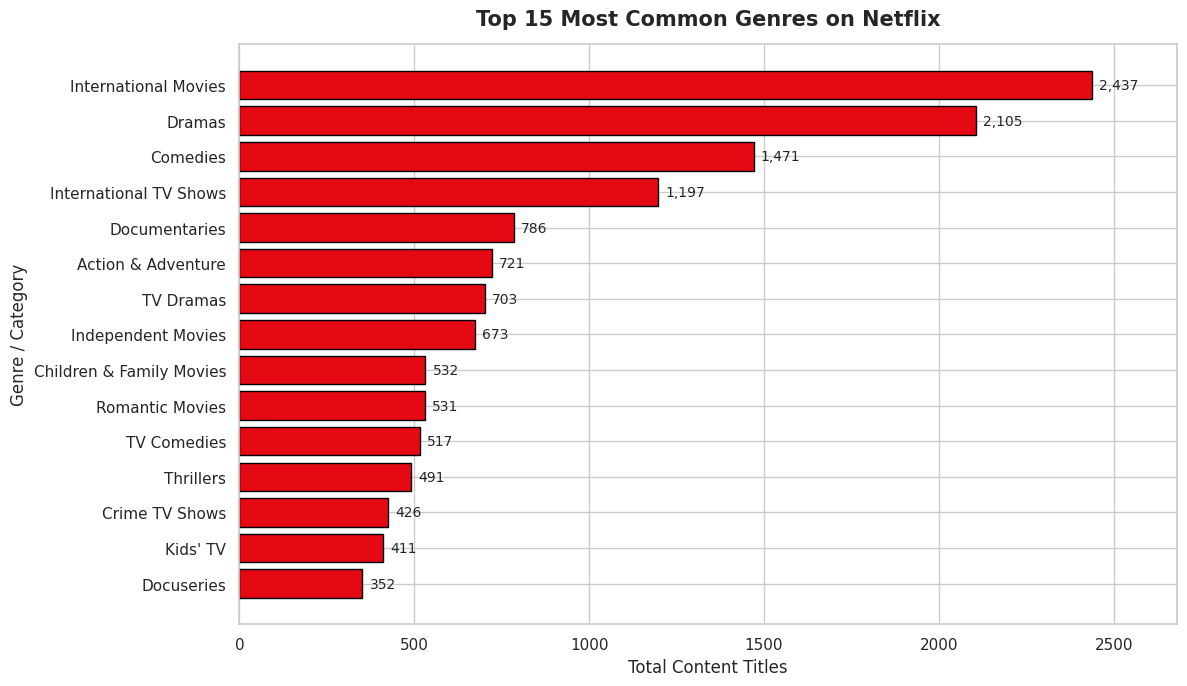

In [26]:
genres_series = netflix["listed_in"].str.split(", ").explode()
top_15_genres = genres_series.value_counts().head(15).sort_values(ascending=True)

plt.figure(figsize=(12, 7))
bars = plt.barh(top_15_genres.index, top_15_genres.values, color="#e50914", edgecolor="black")
plt.title("Top 15 Most Common Genres on Netflix", fontsize=15, fontweight='bold', pad=14)
plt.xlabel("Total Content Titles", fontsize=12)
plt.ylabel("Genre / Category", fontsize=12)

for bar in bars:
    plt.text(bar.get_width() + 20, bar.get_y() + bar.get_height()/2, f"{int(bar.get_width()):,}",
             va='center', ha='left', fontsize=10)

plt.xlim(0, top_15_genres.max() * 1.1)
plt.tight_layout()
plt.show()


### 8.8 Runtime Dynamics: Film Durations & TV Series Seasons
Inspect the runtime distribution of Movies (in minutes) and the longevity profile of TV Shows (in seasons).


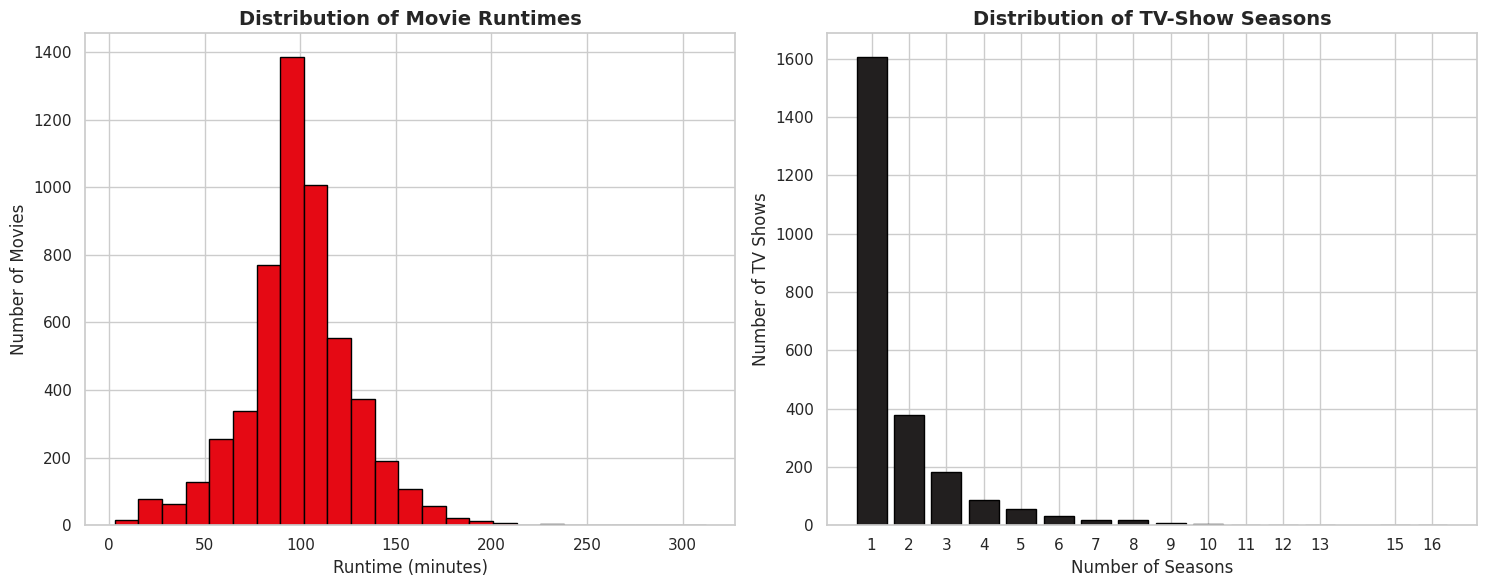

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Safe check: if netflix dataframe was not correctly instantiated globally, fall back to df
if 'netflix' not in globals():
    netflix = df.copy()

# Convert duration column to lowercase to make parsing robust against capitalization differences
duration_clean = netflix["duration"].astype(str).str.lower().str.strip()

# Extract numeric value and unit
duration_parts = duration_clean.str.extract(r"^\s*(\d+)\s*(min|seasons?)\s*$")
netflix["duration_value"] = pd.to_numeric(duration_parts[0], errors="coerce")
netflix["duration_unit"] = duration_parts[1]

# Split movies and tv shows based on catalog type
movies = netflix[netflix["type"] == "Movie"].copy()
tv_shows = netflix[netflix["type"] == "TV Show"].copy()

# Filter values
movie_minutes = movies.loc[movies["duration_unit"] == "min", "duration_value"].dropna()
tv_seasons = tv_shows.loc[
    tv_shows["duration_unit"].str.startswith("season", na=False),
    "duration_value"
].dropna()

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Plot Movie Runtimes
axes[0].hist(movie_minutes, bins=25, color='#e50914', edgecolor="black")
axes[0].set_title("Distribution of Movie Runtimes", fontsize=14, fontweight='bold')
axes[0].set_xlabel("Runtime (minutes)")
axes[0].set_ylabel("Number of Movies")

# Plot TV Show Seasons
season_counts = tv_seasons.value_counts().sort_index()
axes[1].bar(season_counts.index.astype(int), season_counts.values, color='#221f1f', edgecolor='black')
axes[1].set_title("Distribution of TV-Show Seasons", fontsize=14, fontweight='bold')
axes[1].set_xlabel("Number of Seasons")
axes[1].set_ylabel("Number of TV Shows")
axes[1].set_xticks(season_counts.index.astype(int))

plt.tight_layout()
plt.show()



---

## 💡 9. Key Business Insights & Strategic Conclusions

1. **Catalog Proportions & Format Dominance:**
   - Feature films represent approximately **69%** of the catalog, while TV shows comprise **31%**. Although movies offer fast volume, episodic TV shows drive sustained subscriber stickiness.
2. **Parametric Spread & Outlier Profile:**
   - Box plot diagnostics confirm that movie runtimes center tightly around a median of **~100 minutes**, with high-end outliers exceeding 180 minutes. TV show seasons are severely right-skewed: over **70% of shows terminate after 1 season**, illustrating high series attrition or a focus on limited docuseries.
   - The `release_year` box plot identifies vintage titles dating back to 1925, yet the interquartile range (IQR) establishes that the vast majority of assets were produced post-2015.
3. **Geographic Production Dynamics:**
   - The United States remains the primary production hub across both movies and TV series.
   - Multivariate count plots show distinct regional specializations: India's catalog is predominantly feature films, whereas the UK and Japan exhibit a significantly higher ratio of episodic TV content (e.g., British dramas, Anime).
4. **Demographic Maturation & Density Shifts:**
   - Count and violin plot distributions demonstrate that **TV-MA** (Mature Audiences) and **TV-14** are the two largest rating tiers by a wide margin.
   - Kernel density curves highlight a sharp contraction toward modern release dates for TV shows compared to movies, confirming that TV acquisitions focus almost exclusively on contemporary releases.
5. **Strategic Takeaway:**
   - Netflix operates an effective dual-engine acquisition strategy: continually licensing modern, high-turnover feature films to attract casual daily viewers, while producing high-quality original episodic series and international localized content to minimize monthly subscriber churn.

                      ***End of Project***